# Practical Assignment 6: Clustering Algorithms

**Course:** Machine Learning  |  **Dataset:** Wine (chemical analysis of real wines)

### Objective
Apply clustering algorithms to a real-world dataset to find meaningful groups, and evaluate cluster quality with the **Silhouette score**, **Davies-Bouldin index**, **Calinski-Harabasz index** and **visual inspection**.

### Plan
1. Explore and preprocess the data (scaling, PCA for visualisation)
2. **K-Means** – choose k with elbow, silhouette, Davies-Bouldin and Calinski-Harabasz
3. **Agglomerative (hierarchical)** clustering – dendrogram and linkage comparison
4. **DBSCAN** – density-based clustering, parameter search
5. **Gaussian Mixture Model** – probabilistic clustering, BIC
6. Compare all methods, profile the clusters, check stability, and discuss findings

##  Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score,
                             normalized_mutual_info_score)
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_style("whitegrid"); plt.rcParams["figure.dpi"] = 110
print("Libraries loaded.")

Libraries loaded.


## 1. Dataset and Exploratory Analysis
The **Wine dataset** contains 178 wines grown in the same region of Italy, described by **13 chemical measurements** (alcohol, malic acid, flavanoids, colour intensity, proline, ...). The wines come from three different grape cultivars.

**Why this dataset?** It is a real-world, multi-dimensional, unlabeled-style problem where grouping similar products is meaningful (e.g. quality control, product segmentation). The cultivar label is **not used for clustering**. It is kept aside only as an *external check* of whether the discovered clusters make sense.

In [2]:
wine = load_wine(as_frame=True)
X = wine.data.copy()
y_true = wine.target.values          # NOT used for training, only for external validation
print("Shape:", X.shape, "| missing values:", int(X.isna().sum().sum()))
print("Cultivar counts (hidden from the algorithms):", dict(pd.Series(y_true).value_counts().sort_index()))
display(X.describe().T[["mean", "std", "min", "max"]].round(2))

Shape: (178, 13) | missing values: 0
Cultivar counts (hidden from the algorithms): {0: np.int64(59), 1: np.int64(71), 2: np.int64(48)}


,mean,std,min,max
alcohol,13.00,0.81,11.03,14.83
malic_acid,2.34,1.12,0.74,5.80
ash,2.37,0.27,1.36,3.23
alcalinity_of_ash,19.49,3.34,10.60,30.00
magnesium,99.74,14.28,70.00,162.00
total_phenols,2.30,0.63,0.98,3.88
flavanoids,2.03,1.00,0.34,5.08
nonflavanoid_phenols,0.36,0.12,0.13,0.66
proanthocyanins,1.59,0.57,0.41,3.58
color_intensity,5.06,2.32,1.28,13.00


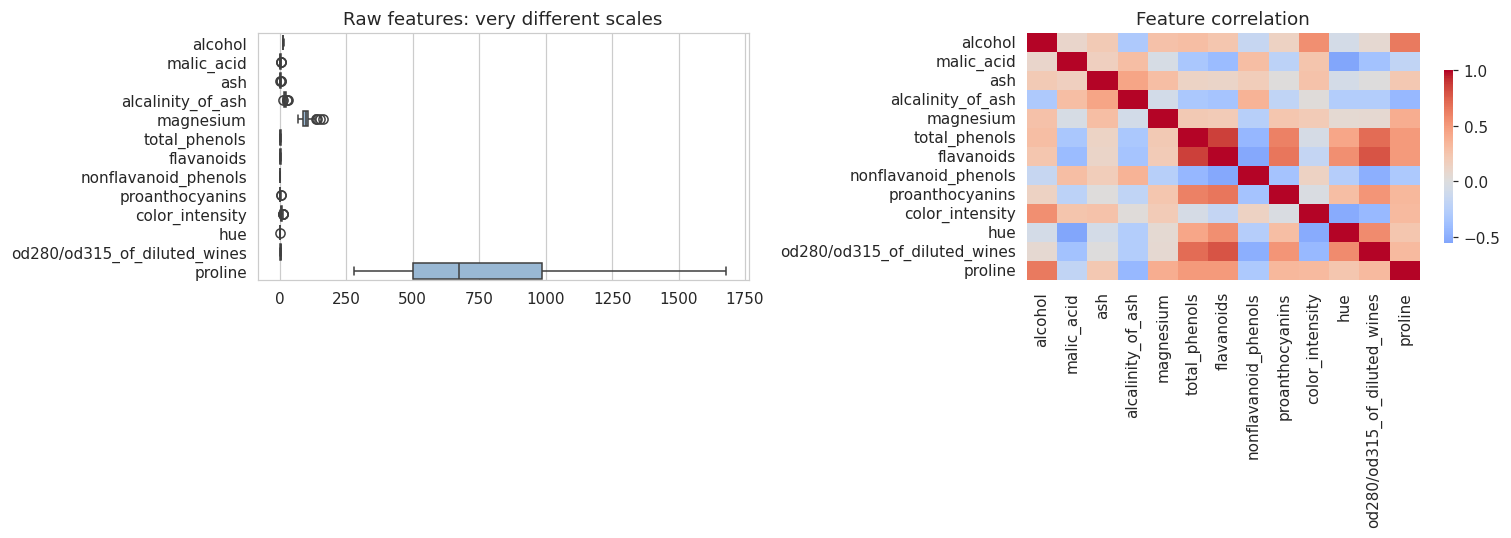

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=X, orient="h", ax=ax[0], color="#8FB8DE"); ax[0].set_title("Raw features: very different scales")
sns.heatmap(X.corr(), cmap="coolwarm", center=0, ax=ax[1], cbar_kws={"shrink": .7})
ax[1].set_title("Feature correlation")
plt.tight_layout(); plt.show()

## 2. Preprocessing
Clustering is **distance-based**, so features with large ranges (e.g. *proline* in the hundreds) would dominate small ones (e.g. *hue*). All features are standardised (mean 0, std 1). **PCA** is used only to project to 2-D for plotting; clustering is done on the full 13-D scaled data.

Variance explained by PC1, PC2: [0.362 0.192] | total: 0.554


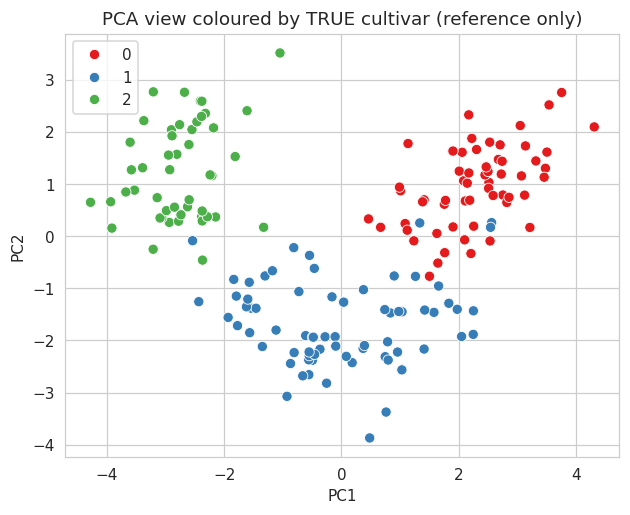

In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
print("Variance explained by PC1, PC2:", pca.explained_variance_ratio_.round(3),
      "| total:", pca.explained_variance_ratio_.sum().round(3))

def scatter_pca(labels, title, ax=None):
    ax = ax or plt.gca()
    sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=labels, palette="Set1", s=45, ax=ax, legend="full")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title(title)

plt.figure(figsize=(6.5, 5)); scatter_pca(y_true, "PCA view coloured by TRUE cultivar (reference only)"); plt.show()

## 3. Evaluation metrics used
| Metric | Type | Best value | Meaning |
|---|---|---|---|
| **Silhouette score** | internal | higher (max 1) | how much closer a point is to its own cluster than to the next one |
| **Davies-Bouldin index** | internal | **lower** (min 0) | average similarity between each cluster and its most similar cluster |
| **Calinski-Harabasz index** | internal | higher | ratio of between-cluster to within-cluster variance |
| **Adjusted Rand Index (ARI)** | external | higher (max 1) | agreement with the true cultivars (chance-corrected) |
| **Normalised Mutual Information (NMI)** | external | higher (max 1) | shared information with the true cultivars |

Internal metrics need no labels and are what you would use in a real project; external metrics are only possible here because this dataset happens to have labels.

In [5]:
def evaluate(X_, labels, with_truth=True):
    mask = labels != -1                       # ignore DBSCAN noise for internal scores
    n_clusters = len(set(labels[mask]))
    out = {"n_clusters": n_clusters, "noise_points": int((~mask).sum())}
    if n_clusters >= 2:
        out["Silhouette"] = silhouette_score(X_[mask], labels[mask])
        out["Davies-Bouldin"] = davies_bouldin_score(X_[mask], labels[mask])
        out["Calinski-Harabasz"] = calinski_harabasz_score(X_[mask], labels[mask])
    if with_truth:
        out["ARI"] = adjusted_rand_score(y_true, labels)
        out["NMI"] = normalized_mutual_info_score(y_true, labels)
    return out

## 4. K-Means
### 4.1 Choosing k
K-Means needs k in advance. We try k = 2 … 10 with `n_init=20` and compare four criteria. If they agree, we can be confident in the choice.

,Inertia (WCSS),Silhouette,Davies-Bouldin,Calinski-Harabasz
k,,,,
2,1658.759,0.259,1.526,69.523
3,1277.928,0.285,1.389,70.940
4,1175.352,0.259,1.817,56.189
5,1107.007,0.232,1.681,47.156
6,1046.002,0.237,1.554,41.701
7,981.595,0.204,1.661,38.686
8,935.201,0.157,1.741,35.805
9,889.893,0.150,1.708,33.807
10,845.895,0.144,1.707,32.397


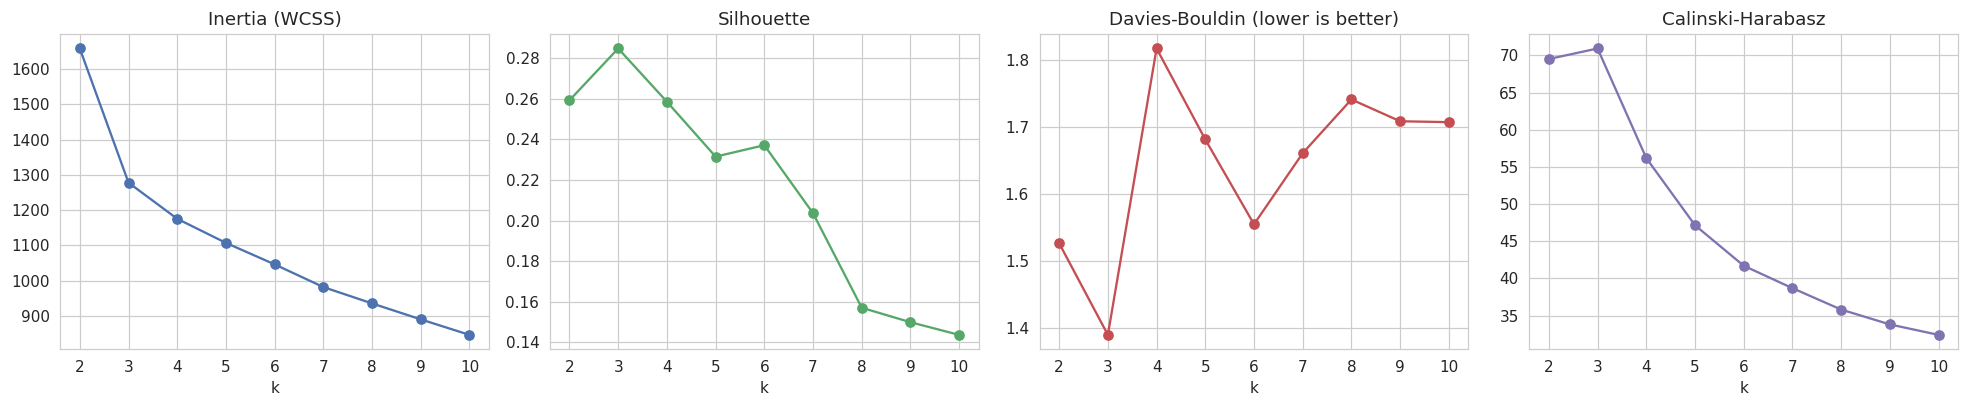

Best k by Silhouette        : 3
Best k by Davies-Bouldin    : 3
Best k by Calinski-Harabasz : 3


In [6]:
K_RANGE = range(2, 11)
rows = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X_scaled)
    rows.append({"k": k, "Inertia (WCSS)": km.inertia_,
                 "Silhouette": silhouette_score(X_scaled, km.labels_),
                 "Davies-Bouldin": davies_bouldin_score(X_scaled, km.labels_),
                 "Calinski-Harabasz": calinski_harabasz_score(X_scaled, km.labels_)})
k_df = pd.DataFrame(rows).set_index("k")
display(k_df.round(3))

fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
for a, col, c in zip(ax, k_df.columns, ["#4C72B0", "#55A868", "#C44E52", "#8172B2"]):
    a.plot(k_df.index, k_df[col], "o-", color=c); a.set_title(col); a.set_xlabel("k")
ax[2].set_title("Davies-Bouldin (lower is better)")
plt.tight_layout(); plt.show()
print("Best k by Silhouette        :", k_df["Silhouette"].idxmax())
print("Best k by Davies-Bouldin    :", k_df["Davies-Bouldin"].idxmin())
print("Best k by Calinski-Harabasz :", k_df["Calinski-Harabasz"].idxmax())

### 4.2 Final K-Means model and silhouette plot
The silhouette plot shows every sample's silhouette value, grouped by cluster. Wide, uniform bars above the average line mean compact, well separated clusters; negative values are samples probably assigned to the wrong cluster.

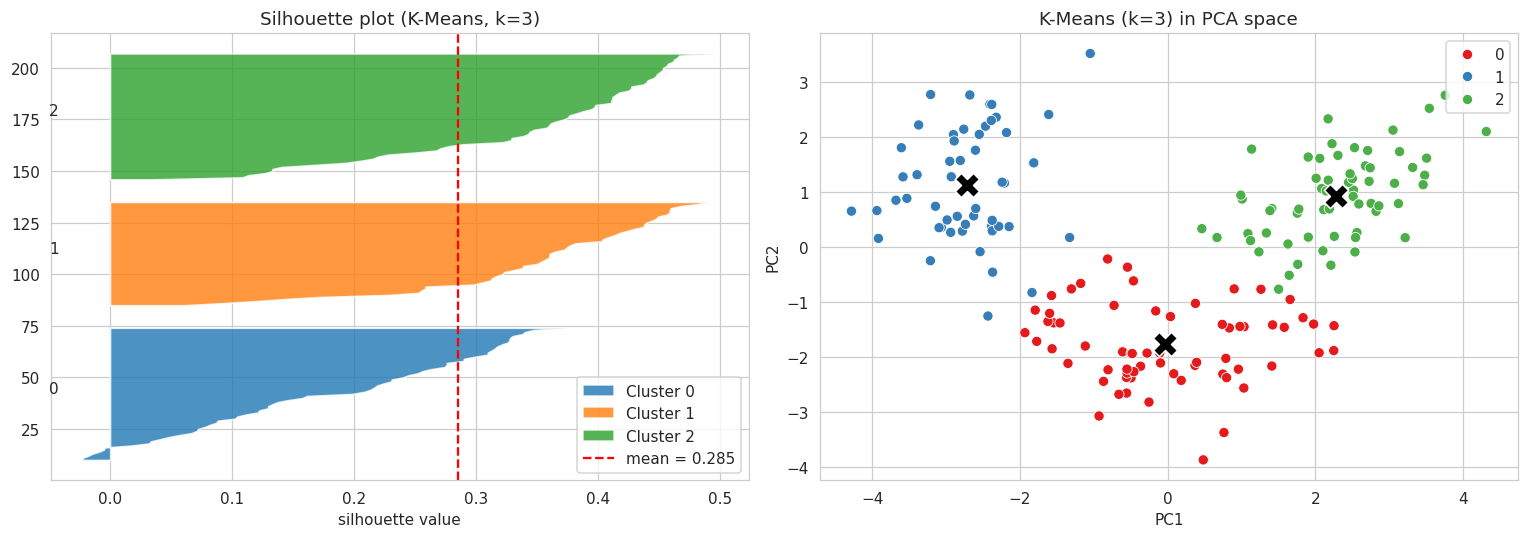

Samples with negative silhouette: 7


In [7]:
BEST_K = int(k_df["Silhouette"].idxmax())
kmeans = KMeans(n_clusters=BEST_K, n_init=20, random_state=RANDOM_STATE).fit(X_scaled)
km_labels = kmeans.labels_

sil_vals = silhouette_samples(X_scaled, km_labels)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
y_lo = 10
for i in range(BEST_K):
    v = np.sort(sil_vals[km_labels == i]); y_hi = y_lo + len(v)
    ax[0].fill_betweenx(np.arange(y_lo, y_hi), 0, v, alpha=0.8, label=f"Cluster {i}")
    ax[0].text(-0.05, y_lo + 0.5 * len(v), str(i)); y_lo = y_hi + 10
ax[0].axvline(sil_vals.mean(), color="red", ls="--", label=f"mean = {sil_vals.mean():.3f}")
ax[0].set_title(f"Silhouette plot (K-Means, k={BEST_K})"); ax[0].set_xlabel("silhouette value"); ax[0].legend()
scatter_pca(km_labels, f"K-Means (k={BEST_K}) in PCA space", ax=ax[1])
cent = pca.transform(kmeans.cluster_centers_)
ax[1].scatter(cent[:, 0], cent[:, 1], marker="X", s=250, c="black", edgecolor="white", label="centroids")
plt.tight_layout(); plt.show()
print("Samples with negative silhouette:", int((sil_vals < 0).sum()))

## 5. Agglomerative (Hierarchical) Clustering
Starts with every point as its own cluster and repeatedly merges the closest pair. The **dendrogram** shows the merge history; a long vertical gap suggests a natural number of clusters. Different **linkage** rules define "closest" differently, so we compare them.

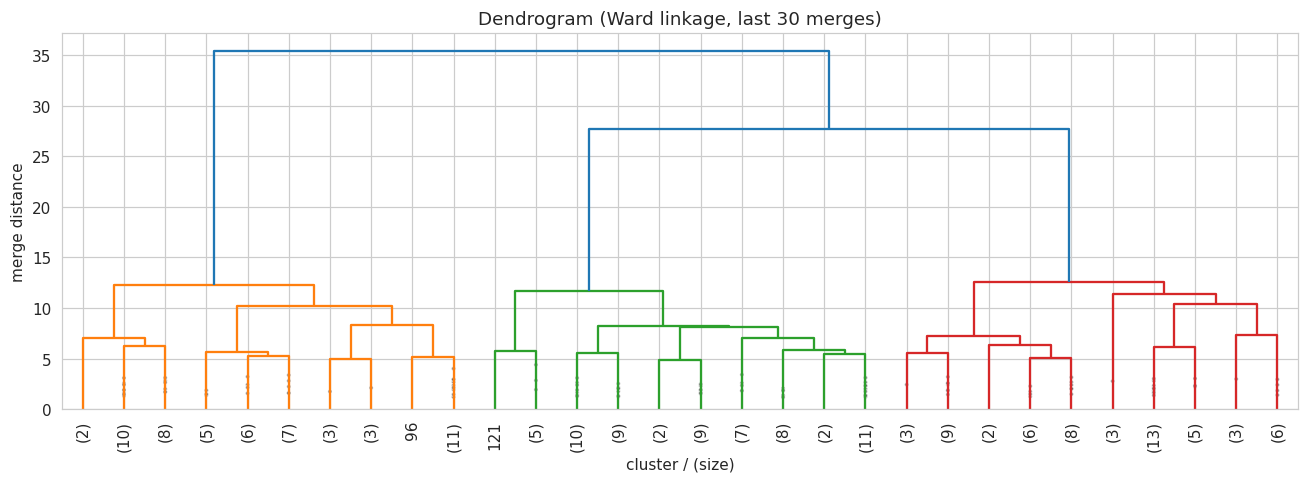

In [8]:
Z = linkage(X_scaled, method="ward")
plt.figure(figsize=(12, 4.5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, show_contracted=True, color_threshold=0.7 * Z[-1, 2])
plt.title("Dendrogram (Ward linkage, last 30 merges)"); plt.xlabel("cluster / (size)"); plt.ylabel("merge distance")
plt.tight_layout(); plt.show()

,n_clusters,noise_points,Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI,NMI
Linkage,,,,,,,
ward,3,0,0.277,1.419,67.647,0.790,0.786
complete,3,0,0.204,1.896,48.990,0.577,0.614
average,3,0,0.158,1.030,4.031,-0.005,0.018
single,3,0,0.183,0.911,4.062,-0.007,0.035


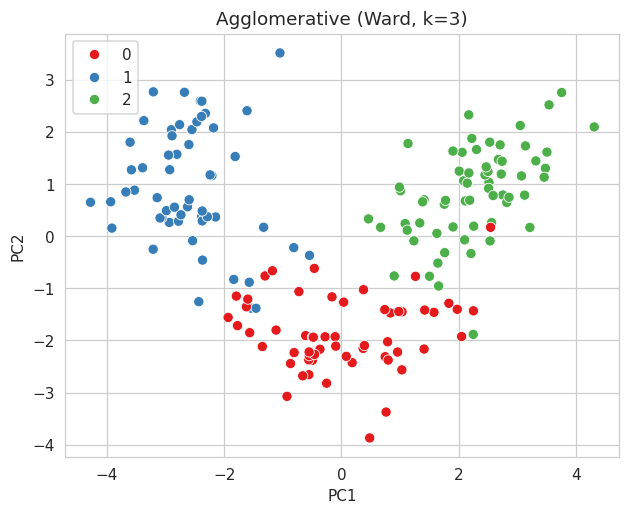

In [9]:
link_rows = []
for link in ["ward", "complete", "average", "single"]:
    lab = AgglomerativeClustering(n_clusters=BEST_K, linkage=link).fit_predict(X_scaled)
    link_rows.append({"Linkage": link, **evaluate(X_scaled, lab)})
link_df = pd.DataFrame(link_rows).set_index("Linkage")
display(link_df.round(3))

agg = AgglomerativeClustering(n_clusters=BEST_K, linkage="ward")
agg_labels = agg.fit_predict(X_scaled)
plt.figure(figsize=(6.5, 5)); scatter_pca(agg_labels, f"Agglomerative (Ward, k={BEST_K})"); plt.show()

## 6. DBSCAN (density-based)
DBSCAN groups points that are densely packed and labels isolated points as **noise (-1)**. It needs no k, but two parameters: `eps` (neighbourhood radius) and `min_samples`. A common rule: `min_samples ≈ 2 × dimensions`, and choose `eps` at the "knee" of the k-distance plot. With 13 dimensions and only 178 points, density is low, so we expect DBSCAN to struggle: a useful point for the comparison.

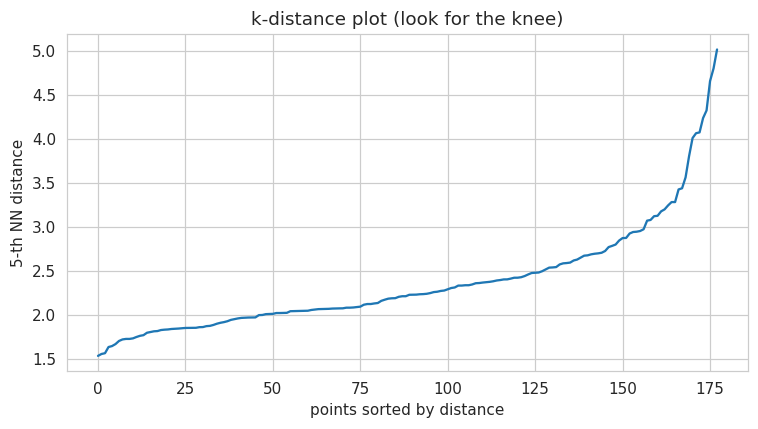

In [10]:
MIN_SAMPLES = 5
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X_scaled)
dist, _ = nn.kneighbors(X_scaled)
kdist = np.sort(dist[:, -1])
plt.figure(figsize=(7, 4)); plt.plot(kdist); plt.xlabel("points sorted by distance"); plt.ylabel(f"{MIN_SAMPLES}-th NN distance")
plt.title("k-distance plot (look for the knee)"); plt.tight_layout(); plt.show()

In [11]:
db_rows = []
for eps in np.arange(1.5, 4.6, 0.25):
    for ms in [3, 5, 8]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        e = evaluate(X_scaled, lab)
        db_rows.append({"eps": round(eps, 2), "min_samples": ms, **e})
db_df = pd.DataFrame(db_rows)
# keep only sensible configs: at least 2 clusters and at most 30% noise
ok = db_df[(db_df["n_clusters"] >= 2) & (db_df["noise_points"] <= 0.3 * len(X_scaled))]
print("Configurations tried:", len(db_df), "| usable (>=2 clusters, <=30% noise):", len(ok))
display(ok.sort_values("Silhouette", ascending=False).head(8).round(3) if len(ok) else db_df.head())

Configurations tried: 39 | usable (>=2 clusters, <=30% noise): 8


,eps,min_samples,n_clusters,noise_points,Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI,NMI
10,2.25,5,2,46,0.337,1.171,71.077,0.396,0.483
9,2.25,3,2,37,0.331,1.184,72.893,0.413,0.514
14,2.50,8,2,30,0.318,1.206,73.115,0.413,0.512
18,3.00,3,2,7,0.239,1.030,6.122,-0.007,0.051
21,3.25,3,2,5,0.237,1.031,6.083,-0.011,0.066
24,3.50,3,2,3,0.231,1.040,5.956,-0.009,0.051
27,3.75,3,2,2,0.228,1.044,5.883,-0.008,0.043
30,4.00,3,2,0,0.222,1.051,5.744,-0.005,0.027


Chosen DBSCAN: eps=2.25, min_samples=5 -> clusters=2, noise=46


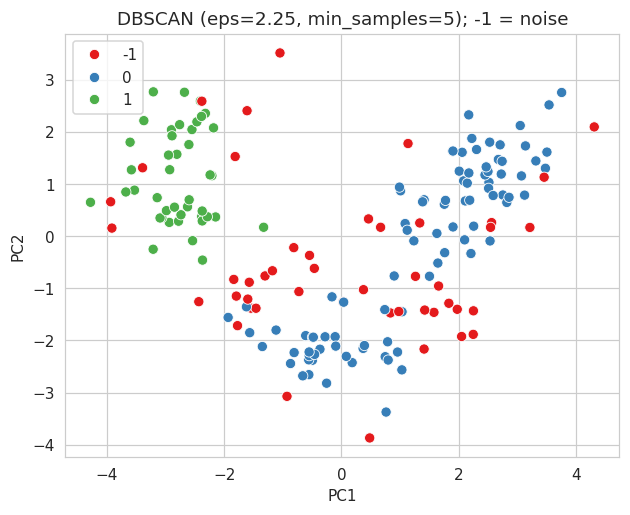

In [12]:
if len(ok):
    best_db = ok.sort_values("Silhouette", ascending=False).iloc[0]
else:
    best_db = db_df.sort_values("noise_points").iloc[0]
EPS, MS = float(best_db["eps"]), int(best_db["min_samples"])
db_labels = DBSCAN(eps=EPS, min_samples=MS).fit_predict(X_scaled)
print(f"Chosen DBSCAN: eps={EPS}, min_samples={MS} -> clusters={len(set(db_labels) - {-1})}, noise={(db_labels == -1).sum()}")
plt.figure(figsize=(6.5, 5)); scatter_pca(db_labels, f"DBSCAN (eps={EPS}, min_samples={MS}); -1 = noise"); plt.show()

## 7. Gaussian Mixture Model (soft clustering)
Models the data as a mixture of Gaussians and gives each point a **probability** of belonging to each cluster. The number of components is chosen with the **BIC** (lower = better; it penalises model complexity).

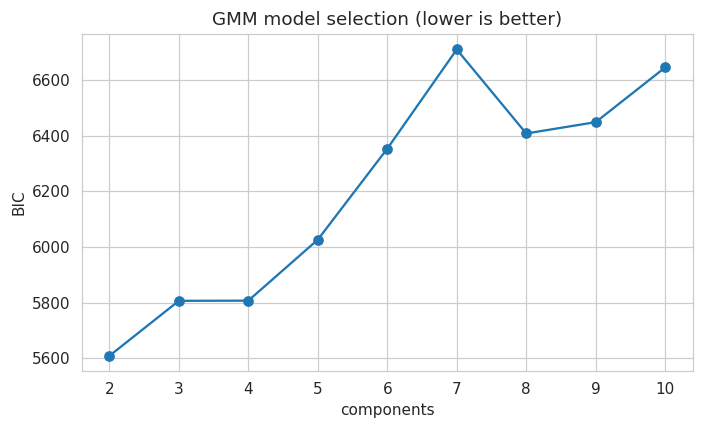

Best number of components by BIC: 2
GMM (k=3): mean assignment confidence = 0.997; samples with confidence < 0.9: 1


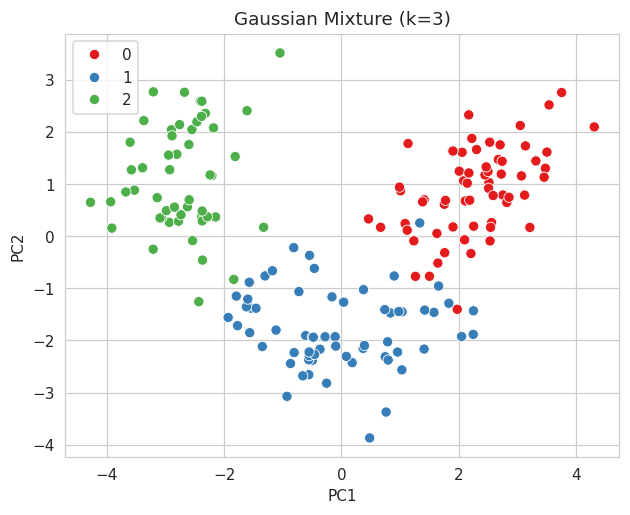

In [13]:
bic = []
for k in K_RANGE:
    g = GaussianMixture(n_components=k, covariance_type="full", n_init=5, random_state=RANDOM_STATE).fit(X_scaled)
    bic.append(g.bic(X_scaled))
plt.figure(figsize=(6.5, 4)); plt.plot(list(K_RANGE), bic, "o-"); plt.xlabel("components"); plt.ylabel("BIC")
plt.title("GMM model selection (lower is better)"); plt.tight_layout(); plt.show()
print("Best number of components by BIC:", list(K_RANGE)[int(np.argmin(bic))])

gmm = GaussianMixture(n_components=BEST_K, covariance_type="full", n_init=5, random_state=RANDOM_STATE).fit(X_scaled)
gmm_labels = gmm.predict(X_scaled)
conf = gmm.predict_proba(X_scaled).max(axis=1)
print(f"GMM (k={BEST_K}): mean assignment confidence = {conf.mean():.3f}; samples with confidence < 0.9: {(conf < 0.9).sum()}")
plt.figure(figsize=(6.5, 5)); scatter_pca(gmm_labels, f"Gaussian Mixture (k={BEST_K})"); plt.show()

## 8. Comparison of all methods

,n_clusters,noise_points,Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI,NMI
K-Means (k=3),3.0,0.0,0.285,1.389,70.940,0.897,0.876
Agglomerative / Ward (k=3),3.0,0.0,0.277,1.419,67.647,0.790,0.786
"DBSCAN (eps=2.25, ms=5)",2.0,46.0,0.337,1.171,71.077,0.396,0.483
GMM (k=3),3.0,0.0,0.284,1.394,70.688,0.880,0.861


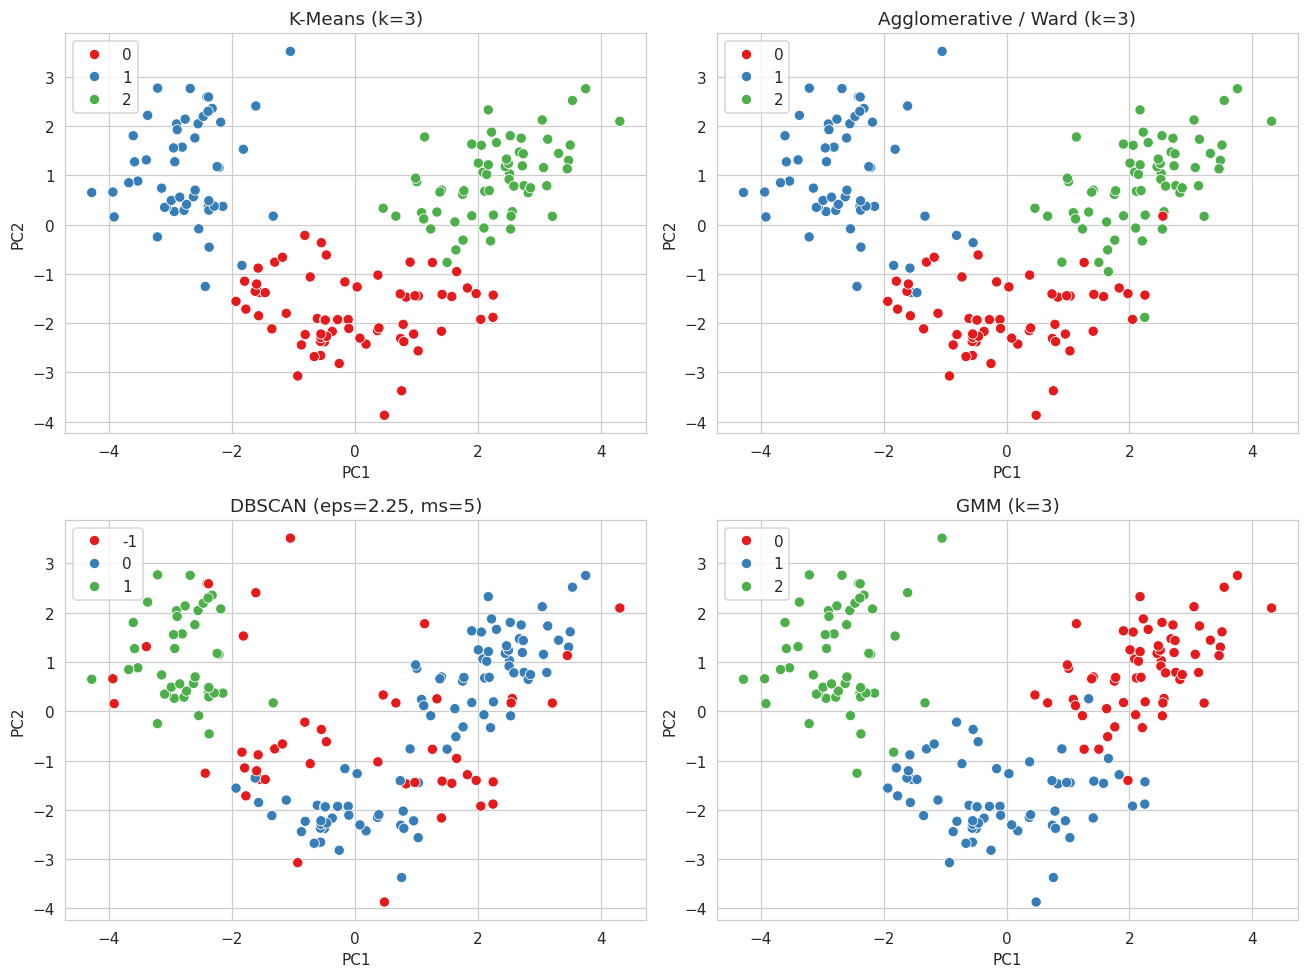

In [14]:
methods = {f"K-Means (k={BEST_K})": km_labels,
           f"Agglomerative / Ward (k={BEST_K})": agg_labels,
           f"DBSCAN (eps={EPS}, ms={MS})": db_labels,
           f"GMM (k={BEST_K})": gmm_labels}
comp = pd.DataFrame({name: evaluate(X_scaled, lab) for name, lab in methods.items()}).T
comp = comp[["n_clusters", "noise_points", "Silhouette", "Davies-Bouldin", "Calinski-Harabasz", "ARI", "NMI"]]
display(comp.round(3))

fig, ax = plt.subplots(2, 2, figsize=(12, 9))
for a, (name, lab) in zip(ax.ravel(), methods.items()):
    scatter_pca(lab, name, ax=a)
plt.tight_layout(); plt.show()

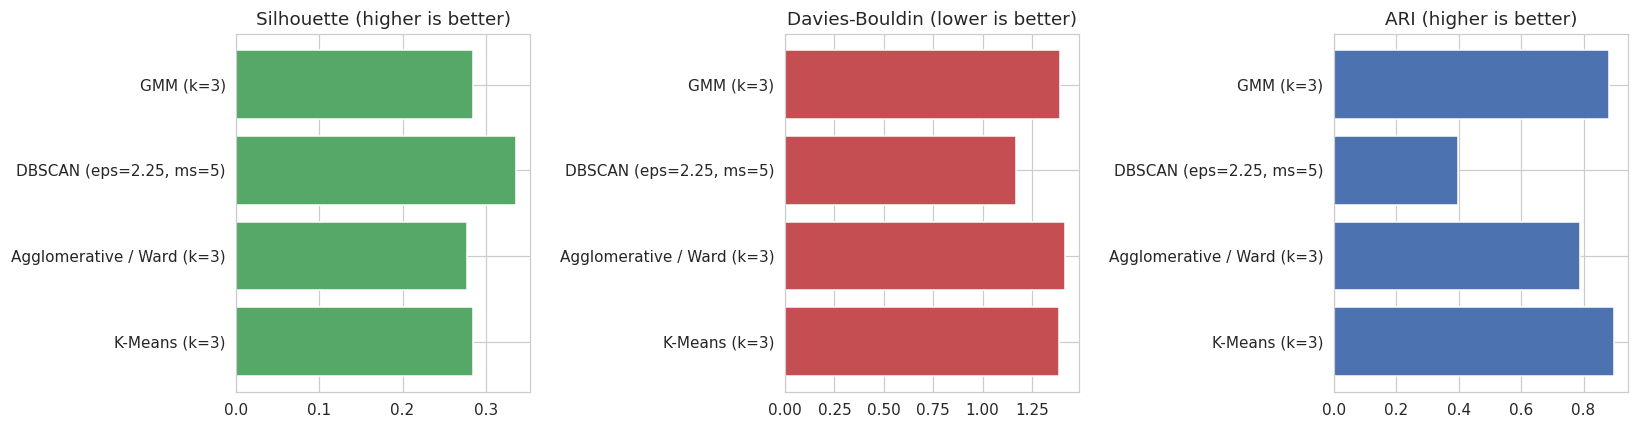

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
plot_df = comp.dropna(subset=["Silhouette"])
for a, col, c in zip(ax, ["Silhouette", "Davies-Bouldin", "ARI"], ["#55A868", "#C44E52", "#4C72B0"]):
    a.barh(plot_df.index, plot_df[col], color=c); a.set_title(col + (" (lower is better)" if col == "Davies-Bouldin" else " (higher is better)"))
plt.tight_layout(); plt.show()

## 9. Cluster profiling – do the clusters mean something?
We interpret the final K-Means clusters by their average chemical profile in the **original units**, and compare them with the hidden cultivars.

Cluster,0,1,2
alcohol,12.25,13.13,13.68
malic_acid,1.90,3.31,2.00
ash,2.23,2.42,2.47
alcalinity_of_ash,20.06,21.24,17.46
magnesium,92.74,98.67,107.97
total_phenols,2.25,1.68,2.85
flavanoids,2.05,0.82,3.00
nonflavanoid_phenols,0.36,0.45,0.29
proanthocyanins,1.62,1.15,1.92
color_intensity,2.97,7.23,5.45


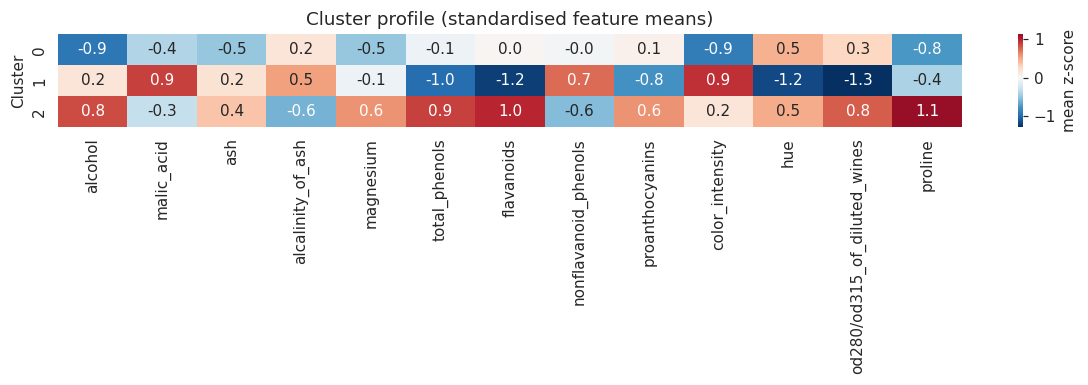

True cultivar,class_0,class_1,class_2
K-Means cluster,,,
0,0,65,0
1,0,3,48
2,59,3,0


In [16]:
profile = X.assign(Cluster=km_labels).groupby("Cluster").mean().round(2)
display(profile.T)

# z-score heatmap: which features define each cluster?
z = pd.DataFrame(X_scaled, columns=X.columns).assign(Cluster=km_labels).groupby("Cluster").mean()
plt.figure(figsize=(11, 3.6))
sns.heatmap(z, annot=True, fmt=".1f", cmap="RdBu_r", center=0, cbar_kws={"label": "mean z-score"})
plt.title("Cluster profile (standardised feature means)"); plt.tight_layout(); plt.show()

display(pd.crosstab(pd.Series(km_labels, name="K-Means cluster"),
                    pd.Series(wine.target_names[y_true], name="True cultivar")))

## 10. Stability check
A trustworthy clustering should not change much if the data is slightly perturbed. We re-cluster 30 bootstrap resamples and compare each result with the original K-Means partition using ARI (on the sampled points).

In [17]:
rng = np.random.RandomState(RANDOM_STATE)
aris = []
for _ in range(30):
    idx = rng.choice(len(X_scaled), size=len(X_scaled), replace=True)
    km_b = KMeans(n_clusters=BEST_K, n_init=10, random_state=int(rng.randint(1e6))).fit(X_scaled[idx])
    aris.append(adjusted_rand_score(km_labels[idx], km_b.predict(X_scaled[idx])))
print(f"Bootstrap stability (ARI vs original partition): mean={np.mean(aris):.3f}, min={np.min(aris):.3f}, std={np.std(aris):.3f}")

# Sensitivity to preprocessing: what if we do NOT scale?
km_raw = KMeans(n_clusters=BEST_K, n_init=20, random_state=RANDOM_STATE).fit(X)
print(f"\nWithout scaling -> Silhouette (raw space)={silhouette_score(X, km_raw.labels_):.3f}, "
      f"ARI vs cultivars={adjusted_rand_score(y_true, km_raw.labels_):.3f}  "
      f"(scaled: ARI={adjusted_rand_score(y_true, km_labels):.3f})")

Bootstrap stability (ARI vs original partition): mean=0.936, min=0.641, std=0.070

Without scaling -> Silhouette (raw space)=0.571, ARI vs cultivars=0.371  (scaled: ARI=0.897)


## 11. Auto-generated summary

In [18]:
print("Best k (Silhouette / DB / CH):", k_df['Silhouette'].idxmax(), "/", k_df['Davies-Bouldin'].idxmin(), "/", k_df['Calinski-Harabasz'].idxmax())
best_internal = comp["Silhouette"].idxmax()
best_external = comp["ARI"].idxmax()
print("Best method by Silhouette:", best_internal, "->", round(comp.loc[best_internal, 'Silhouette'], 3))
print("Best method by ARI       :", best_external, "->", round(comp.loc[best_external, 'ARI'], 3))

Best k (Silhouette / DB / CH): 3 / 3 / 3
Best method by Silhouette: DBSCAN (eps=2.25, ms=5) -> 0.337
Best method by ARI       : K-Means (k=3) -> 0.897


## 12. Findings, Insights and Future Work

### 12.1 What the results show

| Method | Clusters | Noise | Silhouette | Davies-Bouldin ↓ | Calinski-Harabasz | ARI | NMI |
|---|---|---|---|---|---|---|---|
| K-Means (k=3) | 3 | 0 | 0.285 | 1.389 | 70.9 | **0.897** | **0.876** |
| Agglomerative, Ward (k=3) | 3 | 0 | 0.277 | 1.419 | 67.6 | 0.790 | 0.786 |
| GMM (k=3) | 3 | 0 | 0.284 | 1.394 | 70.7 | 0.880 | 0.861 |
| DBSCAN (eps=2.25, min_samples=5) | 2 | 46 | 0.337 | 1.171 | 71.1 | 0.396 | 0.483 |

1. **k = 3 is the best number of clusters.** Silhouette (0.285), Davies-Bouldin (1.389) and Calinski-Harabasz (70.9) all pick k = 3 for K-Means, and the elbow in the inertia curve is also at 3. Three independent criteria agreeing makes this a well supported choice.
2. **K-Means is the best overall method here.** It has the highest agreement with the real cultivars (ARI 0.897; 172 of 178 wines in the matching group) and good stability under resampling (bootstrap ARI mean 0.936). GMM is almost identical (ARI 0.880) and adds soft probabilities (mean confidence 0.997). Ward hierarchical clustering is slightly worse (ARI 0.790).
3. **Absolute silhouette values are modest (about 0.28).** Clusters touch and overlap in the 13-D space (7 samples have a negative silhouette). They are meaningful but not sharply separated, which is typical of real data.
4. **DBSCAN looks best on silhouette (0.337) but is actually the worst.** It found only 2 clusters and labelled 46 of 178 wines (26 %) as noise; silhouette is computed without those points, which flatters it. Its ARI is only 0.396. In 13 dimensions with 178 points the data is too sparse for a single density threshold.
5. **Linkage choice matters for hierarchical clustering.** Average and single linkage produced one huge cluster plus tiny ones (ARI about 0, Calinski-Harabasz about 4) even though their Davies-Bouldin looked "good" (1.03 and 0.91). Ward linkage, which minimises within-cluster variance, was clearly best (ARI 0.790).
6. **Scaling is essential.** Without standardisation the K-Means silhouette looks higher (0.571) but the clusters are driven almost entirely by *proline* and match the cultivars poorly (ARI 0.371 versus 0.897 after scaling). A higher internal score is therefore not automatically a better clustering, and scores cannot be compared across different preprocessing.
7. **The clusters are chemically meaningful.**
   * Cluster 2 (62 wines): high alcohol (13.7), very high proline (about 1100) and high flavanoids (3.0), which corresponds to cultivar 0.
   * Cluster 0 (65 wines): low alcohol (12.3) and low colour intensity (3.0): lighter wines, which correspond to cultivar 1.
   * Cluster 1 (51 wines): high malic acid (3.3), high colour intensity (7.2), low flavanoids (0.8) and low hue: cultivar 2.
8. **Stability:** the K-Means partition is stable on average (bootstrap ARI 0.936) but not perfectly: the worst resample dropped to 0.641, so borderline wines are sensitive to the sample.
9. **GMM model selection:** BIC alone preferred 2 components, whereas the other evidence supports 3. This shows that different criteria can disagree and that domain knowledge should be used.

### 12.2 When to use each method

| Method | Use when | Watch out for |
|---|---|---|
| **K-Means** | Roughly spherical, similar-sized clusters; large datasets; need a fast, simple baseline | Needs k in advance; sensitive to scaling and outliers; assumes round clusters |
| **Hierarchical (Ward)** | Small/medium data; you want the cluster hierarchy (dendrogram) or do not know k | Quadratic memory/time; poor linkage choice can give one giant cluster; merges cannot be undone |
| **DBSCAN** | Arbitrary-shaped clusters, noise/outlier detection, low-dimensional data with clear density differences | Hard to tune eps; struggles in high dimensions and with varying densities |
| **GMM** | Elliptical or overlapping clusters; you need soft (probabilistic) membership | Assumes Gaussian shape; can overfit with many components; slower |

### 12.3 Limitations
* A single, small dataset (178 samples) from one region; the results may not transfer to other data.
* The real labels were used only for validation. In a true unsupervised project only the internal metrics would exist, and those proved unreliable on their own (see points 4, 5 and 6).
* The DBSCAN grid was coarse, and no other algorithms (e.g. spectral clustering, HDBSCAN) were tried.
* PCA shows only 55 % of the variance in two dimensions, so the 2-D plots hide some overlap.

### 12.4 Ethical and societal considerations
Clustering has no ground truth, so the chosen number of groups is a modelling decision, and different metrics or preprocessing give different "groups". When clusters are used to make decisions about people (customer segmentation, credit, hiring, medical triage), they can reinforce bias or unfairly label individuals. Features should be reviewed for sensitive attributes or proxies, the clusters validated with domain experts, and the limits of the grouping communicated honestly. Here the data is about wines, so the risk is low, but the same pipeline on personal data would need privacy and fairness checks.

### 12.5 Suggested further work
* Use HDBSCAN, spectral clustering or K-Medoids and compare.
* Try dimensionality reduction (PCA or UMAP) *before* clustering, and feature selection to drop uninformative variables.
* Apply the gap statistic and consensus clustering for a more rigorous choice of k.
* Test on larger real-world datasets, such as customer-segmentation or mall-customer data, where business interpretation is possible.
* Use soft-cluster probabilities from the GMM to flag borderline wines for expert review.